<a href="https://colab.research.google.com/github/sebastianvettel1212/GrokkingDeepLearning/blob/main/11_Neural_Networks_That_Understand_Language.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 11 — Neural Networks That Understand Language

**Grokking Deep Learning** (Andrew W. Trask) — Tugas 2: *Code Reproduction + Theoretical Deep-Dive*

Bab ini membawa deep learning ke **natural language processing (NLP)**: bagaimana mengubah teks (panjang bervariasi, bukan angka) menjadi matriks, memprediksi sentimen ulasan film, lalu membaca apa yang dipelajari jaringan lewat *word embedding*.

**Isi notebook:**
1. Apa artinya "memahami bahasa"? NLP *supervised*
2. Dataset ulasan film (IMDB) & *bag of words* dengan *one-hot encoding*
3. Memprediksi sentimen ulasan (kode buku)
4. *Embedding layer*: pintasan yang setara secara matematis (dibuktikan)
5. Menafsirkan output: kata apa yang dianggap mirip?
6. *Fill in the blank* (*negative sampling*): makna kata berasal dari **loss**
7. Analogi kata: `king - man + woman ≈ queen`
8. Tanya-jawab konsep, latihan mandiri, dan rangkuman

> **Catatan data:** buku memakai 25.000 ulasan IMDB (`reviews.txt`, `labels.txt`). Fungsi `load_imdb()` mencoba mengunduh data asli; bila tidak ada koneksi internet, notebook memakai **korpus ulasan sintetis** yang dibuat otomatis (sel berlabel jelas) agar seluruh kode tetap bisa dijalankan. Angka akurasi pada output di bawah berasal dari sumber data yang tertulis di output sel pemuatan data.

## 1. Memuat data ulasan film

In [1]:
import numpy as np, sys, urllib.request
from collections import Counter
import matplotlib.pyplot as plt

def synthetic_imdb(n=4000, seed=0):
    """Korpus sintetis (cadangan bila IMDB asli tidak bisa diunduh)."""
    rng = np.random.RandomState(seed)
    pos = "excellent wonderful brilliant superb moving beautiful delightful touching charming gripping amazing hilarious stunning masterpiece enjoyable".split()
    neg = "terrible awful boring dull dreadful unconvincing tedious horrible mediocre pathetic annoying wasted forgettable clumsy bland".split()
    neu = ("the a this that movie film plot actor actress scene story ending director music camera cast script dialogue "
           "was is were had has with and but for in of to on at very really quite somewhat overall again maybe often "
           "i we you they it watched saw felt found thought day night time first last whole part parts people characters "
           "life world man woman family friend town city road house one two three").split()
    reviews, labels = [], []
    for _ in range(n):
        y = rng.randint(2); L = rng.randint(20, 40)
        words = [neu[rng.randint(len(neu))] for _ in range(L)]
        own, other = (pos, neg) if y else (neg, pos)
        k = rng.randint(2, 6); start = rng.randint(0, L - 2*k)
        for j in range(k): words[start + 2*j] = own[rng.randint(len(own))]
        if rng.rand() < 0.5: words[rng.randint(L)] = other[rng.randint(len(other))]
        reviews.append(" ".join(words)); labels.append("positive" if y else "negative")
    return reviews, labels

def load_imdb():
    base = "https://raw.githubusercontent.com/iamtrask/Grokking-Deep-Learning/master/"
    try:
        rv = urllib.request.urlopen(base + "reviews.txt", timeout=8).read().decode().splitlines()
        lb = urllib.request.urlopen(base + "labels.txt", timeout=8).read().decode().upper().splitlines()
        return rv, ["positive" if l.strip() == "POSITIVE" else "negative" for l in lb], "IMDB asli (reviews.txt)"
    except Exception as e:
        r, l = synthetic_imdb()
        return r, l, "SINTETIS (tidak ada koneksi internet / unduhan gagal)"

raw_reviews, raw_labels, source = load_imdb()
print("Sumber data :", source)
print("Jumlah review:", len(raw_reviews))
print("Contoh      :", raw_reviews[0][:100], "->", raw_labels[0])

Sumber data : IMDB asli (reviews.txt)
Jumlah review: 25000
Contoh      : bromwell high is a cartoon comedy . it ran at the same time as some other programs about school life -> positive


## 2. One-hot encoding dan *bag of words*

Jaringan saraf butuh input berukuran tetap. Ide buku: korelasi dengan sentimen ada pada **kata-kata** (mis. *terrible* berkorelasi negatif). Maka setiap ulasan diwakili oleh vektor biner berukuran sebesar kosakata: 1 jika kata muncul, 0 jika tidak. Menjumlahkan vektor *one-hot* kata-kata menghasilkan vektor kalimat.

In [2]:
onehots = {}
onehots['cat'] = np.array([1,0,0,0])
onehots['the'] = np.array([0,1,0,0])
onehots['dog'] = np.array([0,0,1,0])
onehots['sat'] = np.array([0,0,0,1])
sentence = ['the','cat','sat']
x = onehots[sentence[0]] + onehots[sentence[1]] + onehots[sentence[2]]
print("Sent Encoding:" + str(x))

Sent Encoding:[1 1 0 1]


In [3]:
tokens = list(map(lambda x: set(x.split(" ")), raw_reviews))
vocab = set()
for sent in tokens:
    for word in sent:
        if len(word) > 0: vocab.add(word)
vocab = list(vocab)
word2index = {w: i for i, w in enumerate(vocab)}

input_dataset = []
for sent in tokens:
    sent_indices = []
    for word in sent:
        try: sent_indices.append(word2index[word])
        except KeyError: ""
    input_dataset.append(list(set(sent_indices)))
target_dataset = [1 if l == "positive" else 0 for l in raw_labels]
print("Ukuran kosakata:", len(vocab))
print("Indeks kata ulasan pertama:", input_dataset[0][:10], "... target =", target_dataset[0])

Ukuran kosakata: 74073
Indeks kata ulasan pertama: [27657, 50197, 71197, 7199, 50721, 4138, 7218, 31288, 43065, 48195] ... target = 1


## 3. Memprediksi sentimen dengan *embedding layer*

Karena vektor input 0/1, perkalian vektor–matriks `layer_0 · weights_0_1` sama dengan **menjumlahkan baris-baris** `weights_0_1` untuk kata-kata yang muncul. Pada kode di bawah, `weights_0_1[x]` memilih baris tersebut, jauh lebih cepat daripada perkalian matriks penuh. Arsitektur: embedding → sigmoid → linear → sigmoid. (Pada buku, 24.000 ulasan untuk latih dan 1.000 terakhir untuk uji.)

In [4]:
np.random.seed(1)
def sigmoid(x): return 1/(1 + np.exp(-x))

alpha, iterations = (0.01, 2)
hidden_size = 100
weights_0_1 = 0.2*np.random.random((len(vocab), hidden_size)) - 0.1
weights_1_2 = 0.2*np.random.random((hidden_size, 1)) - 0.1
n_test = 400   # buku: 1000 (dari 25.000 review); di sini disesuaikan dengan ukuran data

for it in range(iterations):
    correct, total = (0, 0)
    for i in range(len(input_dataset) - n_test):
        x, y = (input_dataset[i], target_dataset[i])
        layer_1 = sigmoid(np.sum(weights_0_1[x], axis=0))
        layer_2 = sigmoid(np.dot(layer_1, weights_1_2))
        layer_2_delta = layer_2 - y
        layer_1_delta = layer_2_delta.dot(weights_1_2.T)
        weights_0_1[x] -= layer_1_delta * alpha
        weights_1_2 -= np.outer(layer_1, layer_2_delta) * alpha
        if np.abs(layer_2_delta) < 0.5: correct += 1
        total += 1
    print("Iter:%d  Training Accuracy: %.4f" % (it, correct/float(total)))

correct, total = (0, 0)
for i in range(len(input_dataset) - n_test, len(input_dataset)):
    x, y = input_dataset[i], target_dataset[i]
    layer_1 = sigmoid(np.sum(weights_0_1[x], axis=0))
    layer_2 = sigmoid(np.dot(layer_1, weights_1_2))
    if np.abs(layer_2 - y) < 0.5: correct += 1
    total += 1
print("Test Accuracy:", correct / float(total))

Iter:0  Training Accuracy: 0.8384
Iter:1  Training Accuracy: 0.9021
Test Accuracy: 0.815


### Tambahan: bukti bahwa *embedding layer* identik dengan perkalian one-hot

*(Sel ini adalah tambahan di luar kode buku.)* Kita bandingkan `onehot @ W` dengan `W[indices].sum(axis=0)`.

In [5]:
idx = input_dataset[0]
onehot = np.zeros(len(vocab)); onehot[idx] = 1
via_matmul = onehot.dot(weights_0_1)
via_rows   = np.sum(weights_0_1[idx], axis=0)
print("Selisih maksimum:", np.abs(via_matmul - via_rows).max())
import time
# Benchmark pada ukuran seperti buku (kosakata 70.000 x hidden 100); kosakata sintetis kita terlalu kecil untuk perbandingan waktu
V = 70000
W_big = np.random.RandomState(0).rand(V, 100); idx_big = np.random.RandomState(1).choice(V, 100, replace=False)
oh_big = np.zeros(V); oh_big[idx_big] = 1
t=time.time(); [oh_big.dot(W_big) for _ in range(20)]; t1=time.time()-t
t=time.time(); [np.sum(W_big[idx_big],axis=0) for _ in range(20)]; t2=time.time()-t
print("Perkalian penuh: %.4f s | pilih baris: %.4f s | percepatan ~%.0fx" % (t1, t2, t1/t2))

Selisih maksimum: 1.7763568394002505e-15
Perkalian penuh: 0.2551 s | pilih baris: 0.0010 s | percepatan ~257x


## 4. Menafsirkan output: kata apa yang dianggap mirip?

Dua kata punya bobot (baris `weights_0_1`) yang mirip bila memengaruhi prediksi dengan cara yang sama. Kita ukur kemiripan dengan jarak Euclidean negatif. Jaringan ini hanya belajar **sentimen**, sehingga kata dengan polaritas yang sama dianggap mirip, sekalipun maknanya berbeda.

In [6]:
def similar(target, weights, n=6):
    t = weights[word2index[target]]
    scores = Counter()
    for w, i in word2index.items():
        scores[w] = -np.sqrt(np.sum((weights[i] - t)**2))
    return [w for w, _ in scores.most_common(n)]

pos_word = 'beautiful' if 'beautiful' in word2index else vocab[0]
neg_word = 'terrible'  if 'terrible'  in word2index else vocab[1]
print(pos_word, "->", similar(pos_word, weights_0_1))
print(neg_word, "->", similar(neg_word, weights_0_1))

beautiful -> ['beautiful', 'vhs', 'recommended', 'sweet', 'beautifully', 'terrific']
terrible -> ['terrible', 'wasted', 'badly', 'poor', 'boring', 'dull']


In [7]:
# Kata paling "positif" dan paling "negatif" menurut jaringan (jumlah bobot ke output lewat hidden layer)
contrib = Counter()
for w, i in word2index.items():
    h = sigmoid(weights_0_1[i]); contrib[w] = float(h.dot(weights_1_2)[0])
print("Paling positif:", [w for w,_ in contrib.most_common(8)])
print("Paling negatif:", [w for w,_ in contrib.most_common()[:-9:-1]])

Paling positif: ['excellent', 'perfect', 'amazing', 'superb', 'enjoyable', 'wonderful', 'wonderfully', 'today']
Paling negatif: ['worst', 'waste', 'awful', 'poorly', 'boring', 'disappointment', 'dull', 'disappointing']


## 5. *Fill in the blank*: makna kata berasal dari **loss**

Buku menegaskan: yang dipelajari jaringan ditentukan oleh **fungsi loss**-nya. Dengan tugas sentimen, kata hanya dibedakan "positif/negatif". Agar kata belajar makna yang lebih kaya, jaringan diberi tugas **mengisi kata yang hilang** dari kata-kata di sekitarnya (*window*). Karena memprediksi seluruh kosakata mahal, dipakai ***negative sampling***: hanya memprediksi kata target (label 1) ditambah beberapa kata acak (label 0), dengan sigmoid tiap-tiap output.

In [8]:
import random
np.random.seed(1); random.seed(1)
concatenated = []
sentences = []
for sent in raw_reviews[:1500]:
    idxs = [word2index[w] for w in sent.split(" ") if w in word2index]
    sentences.append(idxs); concatenated += idxs
concatenated = np.array(concatenated)

alpha, iterations = (0.05, 3)
hidden_size, window, negative = (50, 4, 5)
weights_0_1 = (np.random.rand(len(vocab), hidden_size) - 0.5) * 0.2
weights_1_2 = np.random.rand(len(vocab), hidden_size) * 0
layer_2_target = np.zeros(negative + 1); layer_2_target[0] = 1

for rev_i, review in enumerate(sentences * iterations):
    for target_i in range(len(review)):
        target_samples = [review[target_i]] + list(concatenated[(np.random.rand(negative) * len(concatenated)).astype('int').tolist()])
        left_context  = review[max(0, target_i - window):target_i]
        right_context = review[target_i + 1:min(len(review), target_i + window)]
        layer_1 = np.mean(weights_0_1[left_context + right_context], axis=0)
        layer_2 = sigmoid(layer_1.dot(weights_1_2[target_samples].T))
        layer_2_delta = layer_2 - layer_2_target
        layer_1_delta = layer_2_delta.dot(weights_1_2[target_samples])
        weights_0_1[left_context + right_context] -= layer_1_delta * alpha
        weights_1_2[target_samples] -= np.outer(layer_2_delta, layer_1) * alpha
    if rev_i % 1500 == 0: print("review ke-%d selesai" % rev_i)
print("Pelatihan fill-in-the-blank selesai")

review ke-0 selesai
review ke-1500 selesai
review ke-3000 selesai
Pelatihan fill-in-the-blank selesai


In [9]:
def similar2(target, n=6):
    t = weights_0_1[word2index[target]]
    scores = Counter()
    for w, i in word2index.items():
        scores[w] = -np.sqrt(np.sum((weights_0_1[i] - t)**2))
    return [w for w, _ in scores.most_common(n)]
for w in [pos_word, neg_word]:
    print(w, "->", similar2(w))

beautiful -> ['beautiful', 'sweet', 'strong', 'attractive', 'settings', 'visual']
terrible -> ['terrible', 'weak', 'poorly', 'wooden', 'incredibly', 'ok']


### Tambahan: visualisasi embedding (PCA dengan NumPy)

*(Tambahan, bukan dari buku.)* Embedding 50 dimensi diproyeksikan ke 2 dimensi lewat SVD untuk melihat apakah kata-kata sentimen mengelompok.

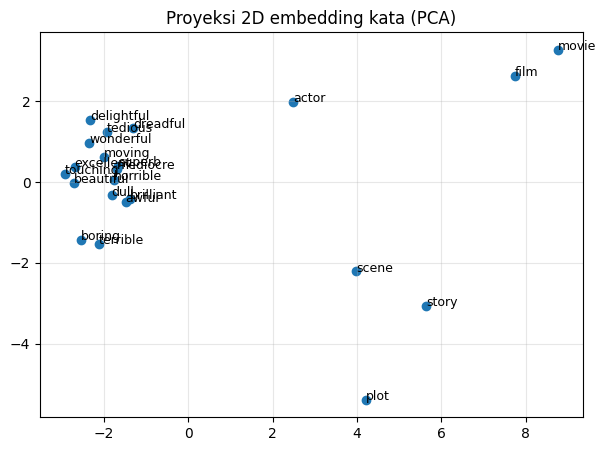

In [10]:
words = [w for w in vocab if w in set("excellent wonderful brilliant superb moving beautiful delightful touching terrible awful boring dull dreadful tedious horrible mediocre movie film plot actor scene story".split())]
if len(words) < 6: words = vocab[:30]
M = np.array([weights_0_1[word2index[w]] for w in words]); M = M - M.mean(0)
U, S, Vt = np.linalg.svd(M, full_matrices=False); P = M @ Vt[:2].T
plt.figure(figsize=(7,5)); plt.scatter(P[:,0], P[:,1])
for (x_, y_), w in zip(P, words): plt.annotate(w, (x_, y_), fontsize=9)
plt.title("Proyeksi 2D embedding kata (PCA)"); plt.grid(alpha=.3); plt.show()

## 6. Analogi kata

Bila sebuah embedding memiliki dimensi yang menyandikan properti (mis. gender dan kebangsawanan), operasi vektor menghasilkan analogi: `king − man + woman ≈ queen`. Pada buku ini ditunjukkan dengan embedding berlatih besar. Karena korpus kita kecil, berikut **ilustrasi tambahan** dengan vektor buatan tangan (dimensi: kebangsawanan, kelelakian, usia-dewasa).

In [11]:
E = {"king":  np.array([0.9, 0.9, 0.8]), "queen": np.array([0.9, 0.1, 0.8]),
     "man":   np.array([0.1, 0.9, 0.8]), "woman": np.array([0.1, 0.1, 0.8]),
     "boy":   np.array([0.1, 0.9, 0.1]), "girl":  np.array([0.1, 0.1, 0.1]),
     "prince":np.array([0.9, 0.9, 0.1])}
def nearest(v, exclude):
    sc = {w: -np.linalg.norm(e - v) for w, e in E.items() if w not in exclude}
    return max(sc, key=sc.get)
v = E["king"] - E["man"] + E["woman"]
print("king - man + woman  ->", nearest(v, {"king","man","woman"}))

king - man + woman  -> queen


## 7. Tanya-jawab konsep

**1. Mengapa teks tidak bisa langsung dimasukkan ke jaringan?** Karena jaringan butuh angka berukuran tetap, sedangkan teks adalah deretan karakter dengan panjang bervariasi. Perlu representasi yang menangkap properti berkorelasi dengan target (di sini: kehadiran kata).

**2. Apa itu one-hot encoding dan mengapa kata yang berulang hanya dihitung sekali?** Vektor biner sepanjang kosakata; 1 menandai kehadiran. Pada bahasa, kehadiran kata umumnya lebih informatif daripada frekuensinya, dan pembatasan 1 mencegah kata umum mendominasi jumlah.

**3. Mengapa embedding layer setara dengan perkalian one-hot, tetapi lebih cepat?** Perkalian vektor one-hot dengan matriks hanya menjumlahkan baris-baris yang berindeks 1; memilih baris langsung menghindari perkalian dengan nol dalam jumlah sangat besar.

**4. Mengapa "terrible" dan kata sentimen negatif lain berembedding mirip pada jaringan sentimen?** Karena loss hanya peduli pada sentimen: kata dengan pengaruh sama terhadap prediksi bergerak ke arah serupa.

**5. Mengapa tugas fill-in-the-blank menghasilkan embedding yang lebih kaya?** Loss menuntut kata dengan konteks serupa memiliki embedding serupa, sehingga makna (distribusi konteks) tertangkap, bukan hanya sentimen.

**6. Apa fungsi negative sampling?** Menghindari softmax atas seluruh kosakata: hanya kata target dan beberapa kata acak yang dihitung, sehingga setiap langkah jauh lebih murah.

## 8. Latihan mandiri (dengan jawaban)

**Latihan 1.** Berapa jumlah bobot `weights_0_1` bila kosakata 70.000 dan hidden 100? **Jawaban:** 70.000 × 100 = 7.000.000.

**Latihan 2.** Mengapa `weights_0_1[x] -= ...` hanya memperbarui baris kata yang muncul? **Jawaban:** Kata yang tidak muncul memiliki input 0, sehingga gradiennya 0; memperbarui baris terpilih saja sama dengan pembaruan penuh namun efisien.

**Latihan 3.** Ubah `window` dari 4 ke 2 dan jalankan ulang bagian 5. Apa yang diharapkan? **Jawaban:** Konteks lebih sempit membuat kemiripan lebih bersifat sintaktis (kata bertetangga langsung); window lebih besar menangkap tema/topik yang lebih luas.

**Latihan 4.** Hitung `queen` dari analogi bila `king=[2,1]`, `man=[1,1]`, `woman=[1,0]`. **Jawaban:** `king − man + woman = [2,0]`; vektor ini dekat dengan embedding `queen` bila `queen` bernilai sekitar `[2,0]`.

## Rangkuman

- Teks diubah menjadi vektor lewat *one-hot / bag of words*; jaringan sentimen mempelajari korelasi kata–label.
- **Embedding layer** = pemilihan baris matriks bobot; identik dengan perkalian one-hot (selisih ≈ 0) namun jauh lebih cepat.
- **Loss menentukan makna**: tugas sentimen hanya menghasilkan embedding bersentimen, sedangkan *fill in the blank* + *negative sampling* menghasilkan embedding berbasis konteks.
- Analogi kata muncul karena properti tersimpan sebagai arah linear dalam ruang embedding.